In [172]:
import pandas as pd

# Load the files
train = pd.read_csv(r"C:\Users\Administrator\Downloads\train.csv")
test = pd.read_csv(r"C:\Users\Administrator\Downloads\test.csv")
features = pd.read_csv(r"C:\Users\Administrator\Downloads\features.csv")
stores = pd.read_csv(r"C:\Users\Administrator\Downloads\stores.csv")

In [173]:
# Check the number of missing values
print("Train missing:", train.isnull().sum().sum())
print("Test missing:", test.isnull().sum().sum())
print("Features missing:", features.isnull().sum().sum())
print("Stores missing:", stores.isnull().sum().sum())

Train missing: 0
Test missing: 0
Features missing: 24040
Stores missing: 0


In [174]:
# Check the number of duplicates
print("Train duplicates:", train.duplicated().sum())
print("Test duplicates:", test.duplicated().sum())
print("Features duplicates:", features.duplicated().sum())
print("Stores duplicates:", stores.duplicated().sum())

Train duplicates: 0
Test duplicates: 0
Features duplicates: 0
Stores duplicates: 0


In [175]:
# Check the percentage missing
missing_percent = features.isnull().mean() * 100

print(missing_percent.sort_values(ascending=False))

MarkDown2       64.334554
MarkDown4       57.704518
MarkDown3       55.885226
MarkDown1       50.769231
MarkDown5       50.549451
CPI              7.142857
Unemployment     7.142857
Store            0.000000
Fuel_Price       0.000000
Temperature      0.000000
Date             0.000000
IsHoliday        0.000000
dtype: float64


In [176]:
# Compare missing vs non-missing
features[features["MarkDown1"].isnull()].head()

features["MarkDown1"].isnull().value_counts()

MarkDown1
True     4158
False    4032
Name: count, dtype: int64

In [177]:
# Check whether missing values occur together
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

features[markdown_cols].isnull().sum()

MarkDown1    4158
MarkDown2    5269
MarkDown3    4577
MarkDown4    4726
MarkDown5    4140
dtype: int64

In [178]:
# How many rows have all markdown variables missing
features[markdown_cols].isnull().all(axis=1).sum()

np.int64(4140)

In [179]:
# Check CPI and unemployment
features[["CPI", "Unemployment"]].isnull().sum()

CPI             585
Unemployment    585
dtype: int64

In [180]:
# Check which stores are affected
features[
    features["CPI"].isnull()
]["Store"].unique()



array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45])

In [181]:
features[
    features["Unemployment"].isnull()
]["Store"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45])

In [182]:
# Check whether CPI and unemployment disappear at the same date
features[
    features["CPI"].isnull() &
    features["Unemployment"].isnull()
].head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
169,1,2013-05-03,66.66,3.386,2298.63,2.00,129.90,55.46,1301.04,NaN,NaN,False
170,1,2013-05-10,63.90,3.392,4624.61,83.88,42.38,1618.31,8144.90,NaN,NaN,False
171,1,2013-05-17,69.53,3.454,16170.50,92.00,8.32,4127.24,6206.97,NaN,NaN,False
172,1,2013-05-24,77.19,3.494,7959.89,178.00,1621.47,3152.57,2938.70,NaN,NaN,False
173,1,2013-05-31,78.02,3.466,2369.77,142.45,475.35,45.55,2056.84,NaN,NaN,False


In [183]:
features[
    features["CPI"].isnull() &
    features["Unemployment"].isnull()
]["Date"].unique()

<StringArray>
['2013-05-03', '2013-05-10', '2013-05-17', '2013-05-24', '2013-05-31',
 '2013-06-07', '2013-06-14', '2013-06-21', '2013-06-28', '2013-07-05',
 '2013-07-12', '2013-07-19', '2013-07-26']
Length: 13, dtype: str

In [184]:
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

print(features[markdown_cols].isnull().sum())
print("\nAll markdowns missing:",
      features[markdown_cols].isnull().all(axis=1).sum())

MarkDown1    4158
MarkDown2    5269
MarkDown3    4577
MarkDown4    4726
MarkDown5    4140
dtype: int64

All markdowns missing: 4140


In [185]:
print(features[["CPI", "Unemployment"]].isnull().sum())

CPI             585
Unemployment    585
dtype: int64


In [186]:
print(
    features[
        features["CPI"].isnull() |
        features["Unemployment"].isnull()
    ][["Store", "Date", "CPI", "Unemployment"]].head(20)
)

     Store        Date  CPI  Unemployment
169      1  2013-05-03  NaN           NaN
170      1  2013-05-10  NaN           NaN
171      1  2013-05-17  NaN           NaN
172      1  2013-05-24  NaN           NaN
173      1  2013-05-31  NaN           NaN
174      1  2013-06-07  NaN           NaN
175      1  2013-06-14  NaN           NaN
176      1  2013-06-21  NaN           NaN
177      1  2013-06-28  NaN           NaN
178      1  2013-07-05  NaN           NaN
179      1  2013-07-12  NaN           NaN
180      1  2013-07-19  NaN           NaN
181      1  2013-07-26  NaN           NaN
351      2  2013-05-03  NaN           NaN
352      2  2013-05-10  NaN           NaN
353      2  2013-05-17  NaN           NaN
354      2  2013-05-24  NaN           NaN
355      2  2013-05-31  NaN           NaN
356      2  2013-06-07  NaN           NaN
357      2  2013-06-14  NaN           NaN


In [187]:
missing_economic = features[
    features["CPI"].isna() &
    features["Unemployment"].isna()
]

print(missing_economic[["Date", "Store"]].head(20))

           Date  Store
169  2013-05-03      1
170  2013-05-10      1
171  2013-05-17      1
172  2013-05-24      1
173  2013-05-31      1
174  2013-06-07      1
175  2013-06-14      1
176  2013-06-21      1
177  2013-06-28      1
178  2013-07-05      1
179  2013-07-12      1
180  2013-07-19      1
181  2013-07-26      1
351  2013-05-03      2
352  2013-05-10      2
353  2013-05-17      2
354  2013-05-24      2
355  2013-05-31      2
356  2013-06-07      2
357  2013-06-14      2


In [188]:
print("Number of unique dates:",
      missing_economic["Date"].nunique())

print("\nDates:")
print(missing_economic["Date"].unique())

Number of unique dates: 13

Dates:
<StringArray>
['2013-05-03', '2013-05-10', '2013-05-17', '2013-05-24', '2013-05-31',
 '2013-06-07', '2013-06-14', '2013-06-21', '2013-06-28', '2013-07-05',
 '2013-07-12', '2013-07-19', '2013-07-26']
Length: 13, dtype: str


In [189]:
features[
    features["CPI"].isna() &
    features["Unemployment"].isna()
].groupby("Date").size()

Date
2013-05-03    45
2013-05-10    45
2013-05-17    45
2013-05-24    45
2013-05-31    45
2013-06-07    45
2013-06-14    45
2013-06-21    45
2013-06-28    45
2013-07-05    45
2013-07-12    45
2013-07-19    45
2013-07-26    45
dtype: int64

In [190]:
# Replace missing values with zero
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

features[markdown_cols] = features[markdown_cols].fillna(0)

In [191]:
features.isnull().sum()

Store             0
Date              0
Temperature       0
Fuel_Price        0
MarkDown1         0
MarkDown2         0
MarkDown3         0
MarkDown4         0
MarkDown5         0
CPI             585
Unemployment    585
IsHoliday         0
dtype: int64

In [192]:
features[
    ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
].isnull().sum()

MarkDown1    0
MarkDown2    0
MarkDown3    0
MarkDown4    0
MarkDown5    0
dtype: int64

In [193]:
print("Total missing values:", features.isnull().sum().sum())

Total missing values: 1170


In [194]:
features["Date"] = pd.to_datetime(features["Date"])

In [195]:
features = features.sort_values(["Store", "Date"])

In [196]:
features["CPI"] = features.groupby("Store")["CPI"].transform(
    lambda x: x.interpolate()
)

features["Unemployment"] = features.groupby("Store")["Unemployment"].transform(
    lambda x: x.interpolate()
)

In [197]:
print(features[["CPI", "Unemployment"]].isnull().sum())

CPI             0
Unemployment    0
dtype: int64


In [198]:
print("Total missing values:", features.isnull().sum().sum())

Total missing values: 0


In [199]:

train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])
features["Date"] = pd.to_datetime(features["Date"])

In [200]:
print(train["Date"].dtype)
print(test["Date"].dtype)
print(features["Date"].dtype)

datetime64[us]
datetime64[us]
datetime64[us]


In [201]:
print(train.describe())

               Store           Dept                        Date   Weekly_Sales
count  421570.000000  421570.000000                      421570  421570.000000
mean       22.200546      44.260317  2011-06-18 08:30:31.963375   15981.258123
min         1.000000       1.000000         2010-02-05 00:00:00   -4988.940000
25%        11.000000      18.000000         2010-10-08 00:00:00    2079.650000
50%        22.000000      37.000000         2011-06-17 00:00:00    7612.030000
75%        33.000000      74.000000         2012-02-24 00:00:00   20205.852500
max        45.000000      99.000000         2012-10-26 00:00:00  693099.360000
std        12.785297      30.492054                         NaN   22711.183519


In [202]:
train.isnull().sum()

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

In [203]:
print(train.columns)

Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday'], dtype='str')


In [204]:
print(train[train["Weekly_Sales"] <= 0][
    ["Store", "Dept", "Date", "Weekly_Sales"]
].head(20))

       Store  Dept       Date  Weekly_Sales
846        1     6 2012-08-10       -139.65
2384       1    18 2012-05-04         -1.27
6048       1    47 2010-02-19       -863.00
6049       1    47 2010-03-12       -698.00
6051       1    47 2010-10-08        -58.00
6055       1    47 2011-03-11          0.00
6056       1    47 2011-04-08       -298.00
6057       1    47 2011-07-08       -198.00
6059       1    47 2011-08-12          0.00
6060       1    47 2011-08-19          0.00
6061       1    47 2011-10-14       -498.00
6062       1    47 2011-12-23       -498.00
6063       1    47 2012-02-17       -198.00
6064       1    47 2012-03-16       -199.00
6163       1    48 2012-03-23       -223.00
6562       1    54 2011-01-21        -50.00
6578       1    54 2011-05-20        -15.00
6616       1    54 2012-03-09        -21.00
12630      2    18 2012-06-01         -1.97
12631      2    18 2012-07-27         -3.03


In [205]:
print(train[train["Weekly_Sales"] <= 0]["Weekly_Sales"].value_counts())

Weekly_Sales
 0.00     73
-15.00    32
-5.00     24
-2.00     18
-2.50     16
          ..
-7.54      1
-10.64     1
-2.45      1
-0.43      1
-1.61      1
Name: count, Length: 679, dtype: int64


In [206]:
non_positive = train[train["Weekly_Sales"] <= 0]

print("Number of non-positive sales:", len(non_positive))

print("\nValue counts:")
print(non_positive["Weekly_Sales"].value_counts().sort_index())

Number of non-positive sales: 1358

Value counts:
Weekly_Sales
-4988.94     1
-3924.00     1
-1750.00     1
-1699.00     1
-1321.48     1
            ..
-0.08        1
-0.07        1
-0.04        2
-0.02        1
 0.00       73
Name: count, Length: 679, dtype: int64


In [207]:
print("Zero sales:", (train["Weekly_Sales"] == 0).sum())
print("Negative sales:", (train["Weekly_Sales"] < 0).sum())

Zero sales: 73
Negative sales: 1285


In [208]:
negative_sales = train[train["Weekly_Sales"] < 0]

display(
    negative_sales[
        ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday"]
    ].head(20)
)

,Store,Dept,Date,Weekly_Sales,IsHoliday
846,1,6,2012-08-10,-139.65,False
2384,1,18,2012-05-04,-1.27,False
6048,1,47,2010-02-19,-863.00,False
6049,1,47,2010-03-12,-698.00,False
6051,1,47,2010-10-08,-58.00,False
6056,1,47,2011-04-08,-298.00,False
6057,1,47,2011-07-08,-198.00,False
6061,1,47,2011-10-14,-498.00,False
6062,1,47,2011-12-23,-498.00,False
6063,1,47,2012-02-17,-198.00,False


In [209]:
print("Most negative sale:", negative_sales["Weekly_Sales"].min())
print("Least negative sale:", negative_sales["Weekly_Sales"].max())

Most negative sale: -4988.94
Least negative sale: -0.02


In [210]:
negative_sales["Dept"].value_counts().head(15)

Dept
47    254
18    180
54    146
19     87
94     77
80     68
49     67
59     44
72     34
78     33
98     27
51     25
45     24
96     22
6      18
Name: count, dtype: int64

In [211]:
negative_sales["Store"].value_counts().head(15)

Store
35    124
18     52
10     50
17     49
15     45
42     44
22     41
31     39
16     38
20     38
39     38
12     37
21     36
25     33
9      32
Name: count, dtype: int64

In [212]:
print(
    negative_sales["IsHoliday"].value_counts()
)

IsHoliday
False    1187
True       98
Name: count, dtype: int64


In [213]:
print("Top departments with negative sales:")
print(negative_sales["Dept"].value_counts().head(15))

Top departments with negative sales:
Dept
47    254
18    180
54    146
19     87
94     77
80     68
49     67
59     44
72     34
78     33
98     27
51     25
45     24
96     22
6      18
Name: count, dtype: int64


In [214]:
print("\nTop stores with negative sales:")
print(negative_sales["Store"].value_counts().head(15))


Top stores with negative sales:
Store
35    124
18     52
10     50
17     49
15     45
42     44
22     41
31     39
16     38
20     38
39     38
12     37
21     36
25     33
9      32
Name: count, dtype: int64


In [215]:
print("Exact duplicate rows:", train.duplicated().sum())

Exact duplicate rows: 0


In [216]:
print(
    "Duplicate Store + Department + Date:",
    train.duplicated(
        subset=["Store", "Dept", "Date"]
    ).sum()
)

Duplicate Store + Department + Date: 0


In [217]:
print("FEATURES exact duplicates:",
      features.duplicated().sum())

print("FEATURES Store + Date duplicates:",
      features.duplicated(
          subset=["Store", "Date"]
      ).sum())

print("TEST exact duplicates:",
      test.duplicated().sum())

print("TEST Store + Dept + Date duplicates:",
      test.duplicated(
          subset=["Store", "Dept", "Date"]
      ).sum())

print("STORES exact duplicates:",
      stores.duplicated().sum())

print("STORES duplicate Store IDs:",
      stores["Store"].duplicated().sum())

FEATURES exact duplicates: 0
FEATURES Store + Date duplicates: 0
TEST exact duplicates: 0
TEST Store + Dept + Date duplicates: 0
STORES exact duplicates: 0
STORES duplicate Store IDs: 0


In [218]:
print("Train stores:", train["Store"].nunique())
print("Test stores:", test["Store"].nunique())
print("Features stores:", features["Store"].nunique())
print("Stores table:", stores["Store"].nunique())

Train stores: 45
Test stores: 45
Features stores: 45
Stores table: 45


In [219]:
print(
    "Train vs Stores:",
    set(train["Store"]) == set(stores["Store"])
)

print(
    "Test vs Stores:",
    set(test["Store"]) == set(stores["Store"])
)

print(
    "Features vs Stores:",
    set(features["Store"]) == set(stores["Store"])
)

Train vs Stores: True
Test vs Stores: True
Features vs Stores: True


In [220]:
print("TRAIN")
print("Start:", train["Date"].min())
print("End:", train["Date"].max())

print("\nTEST")
print("Start:", test["Date"].min())
print("End:", test["Date"].max())

print("\nFEATURES")
print("Start:", features["Date"].min())
print("End:", features["Date"].max())

TRAIN
Start: 2010-02-05 00:00:00
End: 2012-10-26 00:00:00

TEST
Start: 2012-11-02 00:00:00
End: 2013-07-26 00:00:00

FEATURES
Start: 2010-02-05 00:00:00
End: 2013-07-26 00:00:00


In [221]:
train_dates = set(train["Date"].unique())
test_dates = set(test["Date"].unique())

print("Overlapping dates:", len(train_dates.intersection(test_dates)))

Overlapping dates: 0


In [222]:
train_merged = train.merge(
    features,
    on=["Store", "Date"],
    how="left"
)

In [223]:
print("Original train shape:", train.shape)
print("Merged train shape:", train_merged.shape)

Original train shape: (421570, 5)
Merged train shape: (421570, 15)


In [224]:
print(
    train_merged.isnull().sum()
    .sort_values(ascending=False)
)

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday_x     0
Temperature     0
Fuel_Price      0
MarkDown1       0
MarkDown2       0
MarkDown3       0
MarkDown4       0
MarkDown5       0
CPI             0
Unemployment    0
IsHoliday_y     0
dtype: int64


In [225]:
print("Rows before merge:", len(train))
print("Rows after merge:", len(train_merged))

Rows before merge: 421570
Rows after merge: 421570


In [226]:
train_merged = train_merged.merge(
    stores,
    on="Store",
    how="left"
)

In [227]:
print("Merged shape:", train_merged.shape)
print("Missing values:", train_merged.isnull().sum().sum())

Merged shape: (421570, 17)
Missing values: 0


In [228]:
print(train_merged.columns.tolist())

['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday_x', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday_y', 'Type', 'Size']


In [229]:
train_merged.shape

(421570, 17)

In [230]:
train_merged.columns.tolist()

['Store',
 'Dept',
 'Date',
 'Weekly_Sales',
 'IsHoliday_x',
 'Temperature',
 'Fuel_Price',
 'MarkDown1',
 'MarkDown2',
 'MarkDown3',
 'MarkDown4',
 'MarkDown5',
 'CPI',
 'Unemployment',
 'IsHoliday_y',
 'Type',
 'Size']

In [231]:
train_merged.isnull().sum()

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday_x     0
Temperature     0
Fuel_Price      0
MarkDown1       0
MarkDown2       0
MarkDown3       0
MarkDown4       0
MarkDown5       0
CPI             0
Unemployment    0
IsHoliday_y     0
Type            0
Size            0
dtype: int64

In [232]:
(train_merged["IsHoliday_x"] == train_merged["IsHoliday_y"]).all()

np.True_

In [233]:
(train_merged["Type_x"] == train_merged["Type_y"]).all()

KeyError: 'Type_x'

In [ ]:
(train_merged["Size_x"] == train_merged["Size_y"]).all()

np.True_

In [ ]:
train_merged = train_merged.drop(
    columns=["IsHoliday_y", "Type_y", "Size_y"]
)

train_merged = train_merged.rename(
    columns={
        "IsHoliday_x": "IsHoliday",
        "Type_x": "Type",
        "Size_x": "Size"
    }
)

In [ ]:
train_merged.columns.tolist()

['Store',
 'Dept',
 'Date',
 'Weekly_Sales',
 'IsHoliday',
 'Temperature',
 'Fuel_Price',
 'MarkDown1',
 'MarkDown2',
 'MarkDown3',
 'MarkDown4',
 'MarkDown5',
 'CPI',
 'Unemployment',
 'Type',
 'Size']

In [ ]:
train_merged.shape

(421570, 16)

In [ ]:
len(train_merged.columns)

16

In [ ]:
train_merged.isnull().sum()

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
Temperature     0
Fuel_Price      0
MarkDown1       0
MarkDown2       0
MarkDown3       0
MarkDown4       0
MarkDown5       0
CPI             0
Unemployment    0
Type            0
Size            0
dtype: int64

In [ ]:
train_merged.isnull().sum().sum()

np.int64(0)

In [ ]:
train_merged["Weekly_Sales"].describe()

count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64

In [ ]:
train_merged["Weekly_Sales"].sum()

np.float64(6737218987.110001)

In [ ]:
print("Stores:", train_merged["Store"].nunique())
print("Departments:", train_merged["Dept"].nunique())
print("Dates:", train_merged["Date"].nunique())

Stores: 45
Departments: 81
Dates: 143


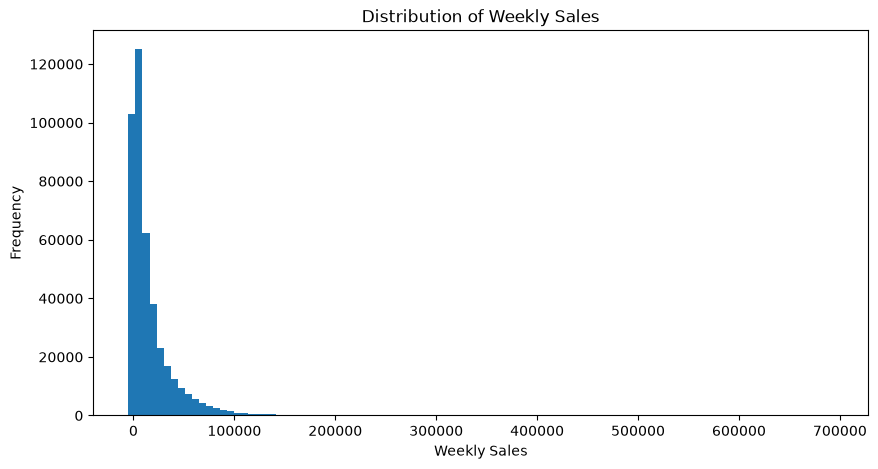

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(train_merged["Weekly_Sales"], bins=100)
plt.xlabel("Weekly Sales")
plt.ylabel("Frequency")
plt.title("Distribution of Weekly Sales")
plt.show()

In [ ]:
print("Mean:", train_merged["Weekly_Sales"].mean())
print("Median:", train_merged["Weekly_Sales"].median())

Mean: 15981.258123467042
Median: 7612.03


In [ ]:
store_sales = (
    train_merged.groupby("Store")["Weekly_Sales"]
    .mean()
    .sort_values(ascending=False)
)

store_sales.head(10)

Store
20    29508.301592
4     29161.210415
14    28784.851727
13    27355.136891
2     26898.070031
10    26332.303819
27    24826.984536
6     21913.243624
1     21710.543621
39    21000.763562
Name: Weekly_Sales, dtype: float64

In [ ]:
store_sales.tail(10)

Store
30    8764.237719
36    8584.412563
7     8358.766148
29    8158.810609
16    7863.224124
38    7492.478460
3     6373.033983
44    6038.929814
33    5728.414053
5     5053.415813
Name: Weekly_Sales, dtype: float64

In [ ]:
# ( Store-level analysis revealed substantial variation in average weekly sales, 
# with the highest-performing stores generating several times the average weekly sales of the 
# lowest-performing stores. This indicates strong store-level differences that should be 
# incorporated into the forecasting models.)

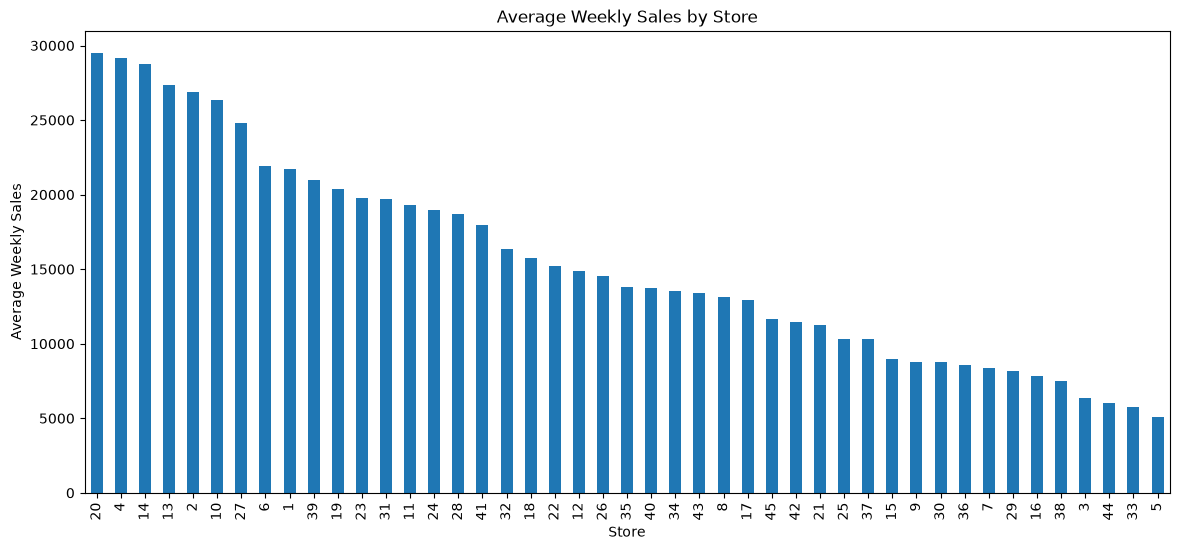

In [ ]:
store_sales.plot(kind="bar", figsize=(14, 6))

plt.xlabel("Store")
plt.ylabel("Average Weekly Sales")
plt.title("Average Weekly Sales by Store")
plt.show()

In [ ]:
dept_sales = (
    train_merged.groupby("Dept")["Weekly_Sales"]
    .mean()
    .sort_values(ascending=False)
)

dept_sales.head(10)

Dept
92    75204.870531
95    69824.423080
38    61090.619568
72    50566.515417
65    45441.706224
90    45232.084488
40    44900.702727
2     43607.020113
91    33687.910758
94    33405.883963
Name: Weekly_Sales, dtype: float64

In [ ]:
dept_sales.tail(10)

Dept
99    415.487065
60    347.370229
77    328.961800
54    108.305985
45     23.211586
51     21.931729
39     11.123750
78      7.296638
43      1.193333
47     -7.682554
Name: Weekly_Sales, dtype: float64

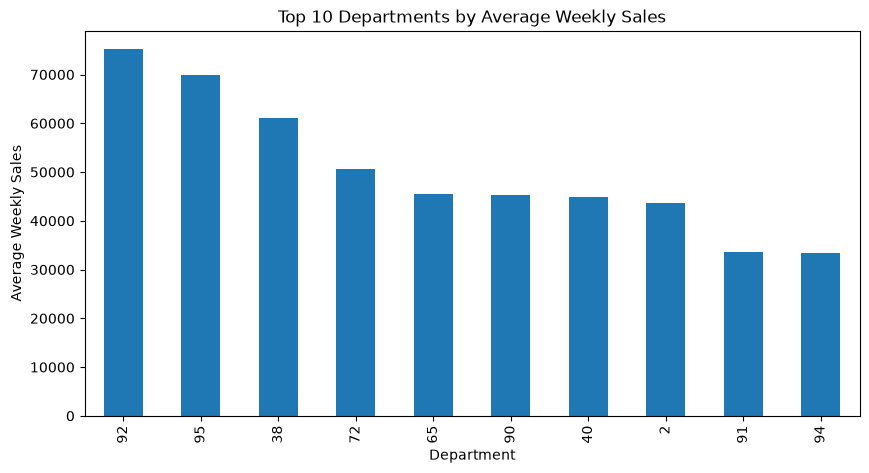

In [ ]:
dept_sales.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Department")
plt.ylabel("Average Weekly Sales")
plt.title("Top 10 Departments by Average Weekly Sales")
plt.show()

In [ ]:
# Trend on date sales
daily_sales = (
    train_merged.groupby("Date")["Weekly_Sales"]
    .sum()
)

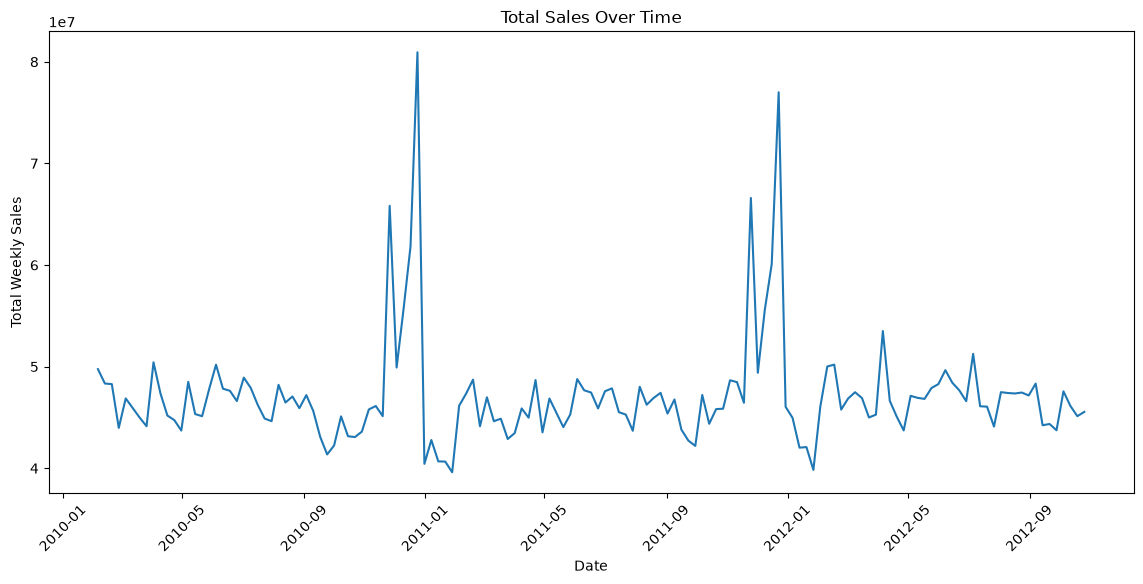

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(daily_sales)

plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.title("Total Sales Over Time")
plt.xticks(rotation=45)
plt.show()

In [ ]:
monthly_sales = (
    train_merged
    .set_index("Date")["Weekly_Sales"]
    .resample("ME")
    .sum()
)

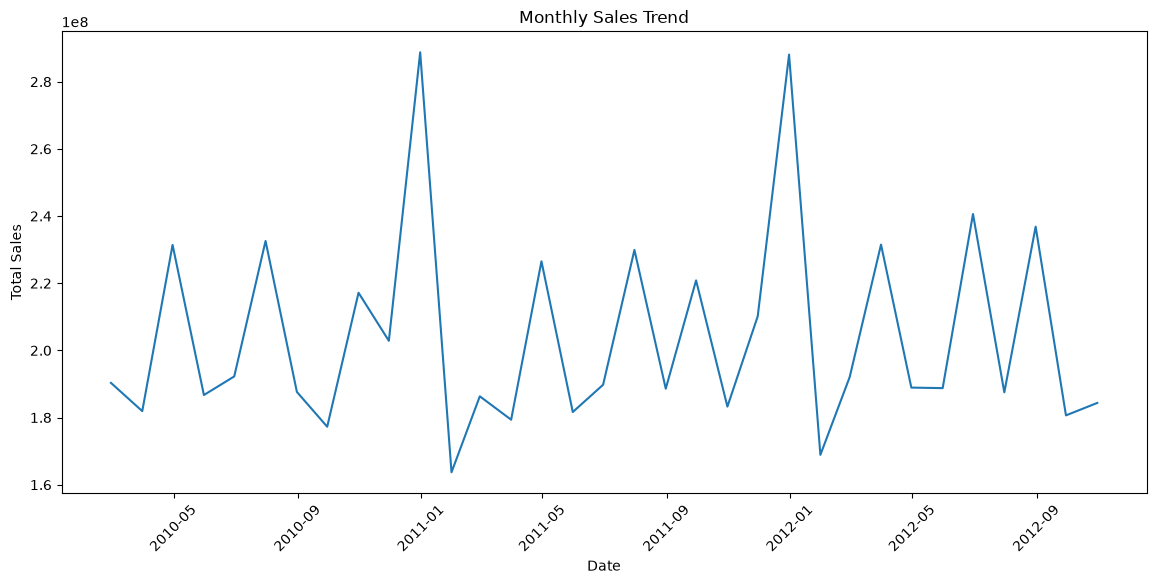

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(monthly_sales)

plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.xticks(rotation=45)
plt.show()

In [ ]:
top_weeks = (
    train_merged.groupby("Date")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_weeks

Date
2010-12-24    80931415.60
2011-12-23    76998241.31
2011-11-25    66593605.26
2010-11-26    65821003.24
2010-12-17    61820799.85
2011-12-16    60085695.94
2010-12-10    55666770.39
2011-12-09    55561147.70
2012-04-06    53502315.87
2012-07-06    51253021.88
Name: Weekly_Sales, dtype: float64

In [ ]:
holiday_sales = (
    train_merged.groupby("IsHoliday")["Weekly_Sales"]
    .agg(["mean", "median", "sum", "count"])
)

holiday_sales

,mean,median,sum,count
IsHoliday,,,,
False,15901.445069,7589.95,6.231919e+09,391909
True,17035.823187,7947.74,5.052996e+08,29661


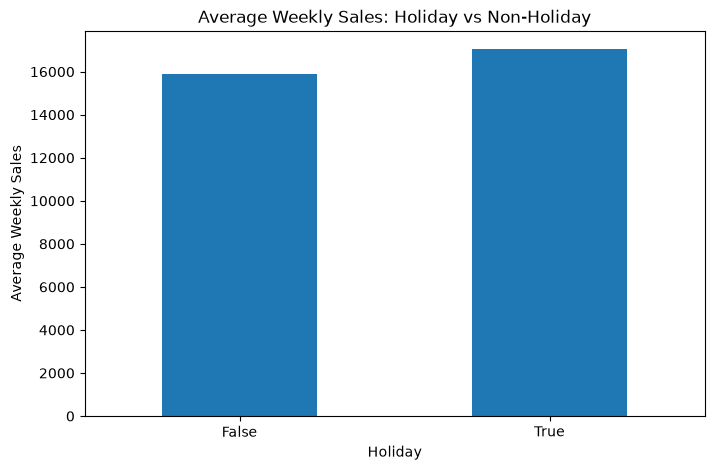

In [ ]:
# Holiday effect on sales
holiday_sales["mean"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Holiday")
plt.ylabel("Average Weekly Sales")
plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Pattern in monthly sales
monthly_pattern = (
    train_merged
    .groupby(train_merged["Date"].dt.month)["Weekly_Sales"]
    .mean()
)

monthly_pattern

Date
1     14126.075111
2     16008.779217
3     15416.657597
4     15650.338357
5     15776.337202
6     16326.137002
7     15861.419650
8     16062.516933
9     15095.886154
10    15243.855576
11    17491.031424
12    19355.702141
Name: Weekly_Sales, dtype: float64

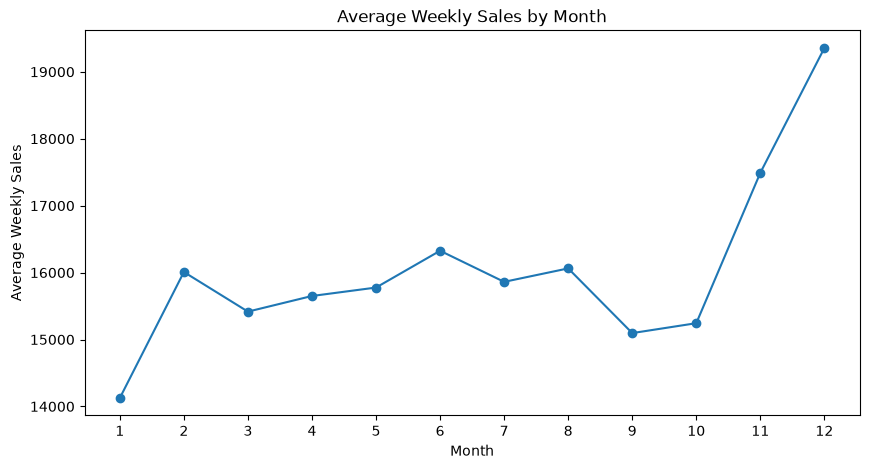

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Weekly Sales")
plt.title("Average Weekly Sales by Month")
plt.xticks(range(1, 13))
plt.show()

In [ ]:
train_merged["Year"] = train_merged["Date"].dt.year
train_merged["Month"] = train_merged["Date"].dt.month

year_month_sales = (
    train_merged
    .groupby(["Year", "Month"])["Weekly_Sales"]
    .mean()
    .reset_index()
)

year_month_sales.head(15)

,Year,Month,Weekly_Sales
0,2010,2,16076.778701
1,2010,3,15432.626612
2,2010,4,15745.551340
3,2010,5,15996.481695
4,2010,6,16486.250953
5,2010,7,15972.812718
6,2010,8,16171.689295
7,2010,9,15120.086691
8,2010,10,14806.151498
9,2010,11,17320.130647


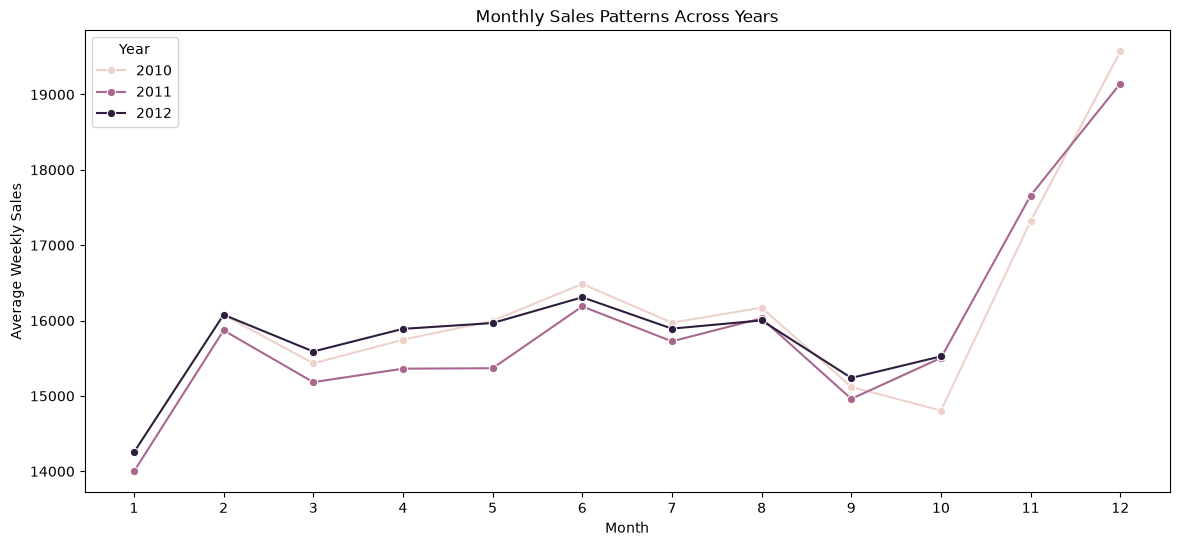

In [ ]:
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=year_month_sales,
    x="Month",
    y="Weekly_Sales",
    hue="Year",
    marker="o"
)

plt.title("Monthly Sales Patterns Across Years")
plt.xlabel("Month")
plt.ylabel("Average Weekly Sales")
plt.xticks(range(1, 13))
plt.show()

In [ ]:
#Store size against sales
store_analysis = (
    train_merged
    .groupby("Store")
    .agg(
        Average_Sales=("Weekly_Sales", "mean"),
        Store_Size=("Size", "first")
    )
    .reset_index()
)

store_analysis.head()

,Store,Average_Sales,Store_Size
0,1,21710.543621,151315
1,2,26898.070031,202307
2,3,6373.033983,37392
3,4,29161.210415,205863
4,5,5053.415813,34875


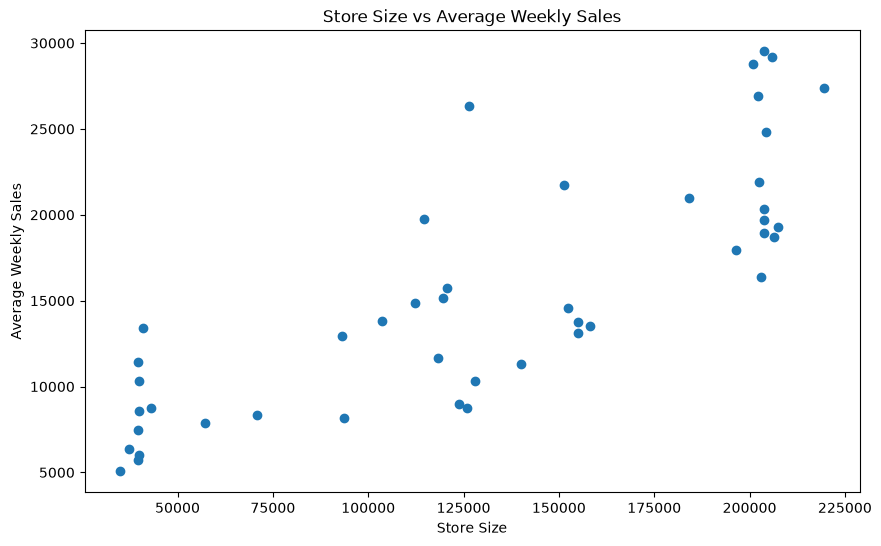

In [235]:
plt.figure(figsize=(10, 6))

plt.scatter(
    store_analysis["Store_Size"],
    store_analysis["Average_Sales"]
)

plt.xlabel("Store Size")
plt.ylabel("Average Weekly Sales")
plt.title("Store Size vs Average Weekly Sales")
plt.show()

In [236]:
store_analysis["Store_Size"].corr(
    store_analysis["Average_Sales"]
)

np.float64(0.8072306200650589)

In [237]:
type_sales = (
    train_merged
    .groupby("Type")["Weekly_Sales"]
    .agg(["mean", "median", "sum", "count"])
)

type_sales

,mean,median,sum,count
Type,,,,
A,20099.568043,10105.17,4.331015e+09,215478
B,12237.075977,6187.87,2.000701e+09,163495
C,9519.532538,1149.67,4.055035e+08,42597


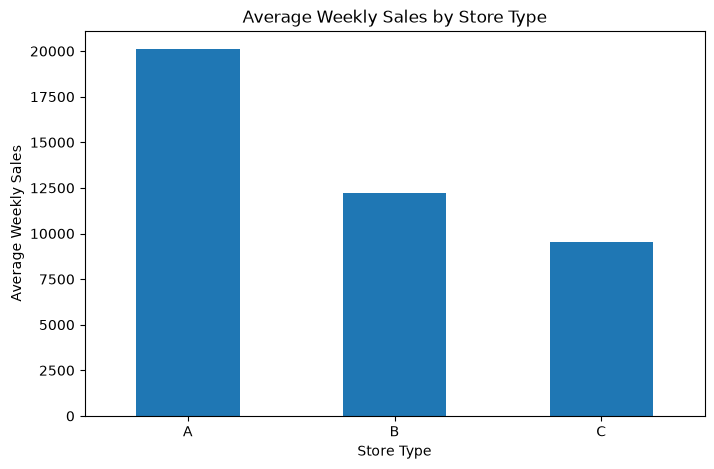

In [238]:
type_sales["mean"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Store Type")
plt.ylabel("Average Weekly Sales")
plt.title("Average Weekly Sales by Store Type")
plt.xticks(rotation=0)
plt.show()

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv(r"C:\Users\Administrator\Downloads\train.csv")
test = pd.read_csv(r"C:\Users\Administrator\Downloads\test.csv")
features = pd.read_csv(r"C:\Users\Administrator\Downloads\features.csv")
stores = pd.read_csv(r"C:\Users\Administrator\Downloads\stores.csv")

In [5]:
train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])
features["Date"] = pd.to_datetime(features["Date"])

markdown_cols = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

features[markdown_cols] = features[markdown_cols].fillna(0)

features = features.sort_values(["Store", "Date"])

features["CPI"] = features.groupby("Store")["CPI"].transform(
    lambda x: x.interpolate()
)

features["Unemployment"] = features.groupby("Store")["Unemployment"].transform(
    lambda x: x.interpolate()
)

In [6]:
train_merged = train.merge(
    features,
    on=["Store", "Date"],
    how="left"
)

train_merged = train_merged.merge(
    stores,
    on="Store",
    how="left"
)

In [7]:
train_merged.shape

(421570, 17)

In [9]:
train_merged = train_merged.drop(
    columns=["IsHoliday_y"]
)

train_merged = train_merged.rename(
    columns={
        "IsHoliday_x": "IsHoliday",
       
    }
)

In [10]:
train_merged.shape

(421570, 16)

In [11]:
type_sales = (
    train_merged
    .groupby("Type")["Weekly_Sales"]
    .agg(["mean", "median", "sum", "count"])
)

type_sales

,mean,median,sum,count
Type,,,,
A,20099.568043,10105.17,4.331015e+09,215478
B,12237.075977,6187.87,2.000701e+09,163495
C,9519.532538,1149.67,4.055035e+08,42597


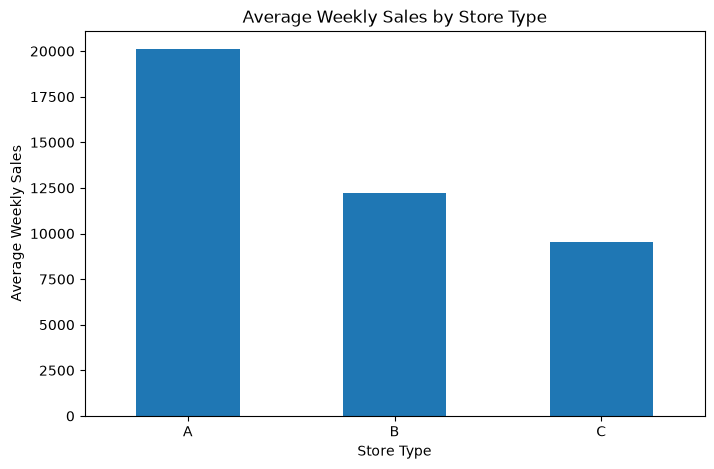

In [12]:
type_sales["mean"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Store Type")
plt.ylabel("Average Weekly Sales")
plt.title("Average Weekly Sales by Store Type")
plt.xticks(rotation=0)
plt.show()

In [13]:
# Store type analysis showed clear differences in sales performance, with Type A stores recording the highest average weekly sales
# and Type C stores the lowest. This indicates that store type is an important factor associated with Walmart's sales and should be 
#included as a predictive feature.

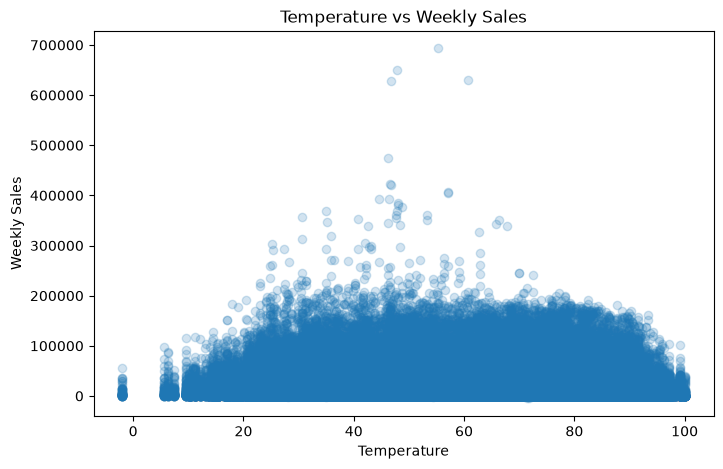

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    train_merged["Temperature"],
    train_merged["Weekly_Sales"],
    alpha=0.2
)

plt.xlabel("Temperature")
plt.ylabel("Weekly Sales")
plt.title("Temperature vs Weekly Sales")

plt.show()

In [17]:
train_merged[["Temperature", "Weekly_Sales"]].corr() 

,Temperature,Weekly_Sales
Temperature,1.000000,-0.002312
Weekly_Sales,-0.002312,1.000000


In [21]:
# Temperature showed almost no linear correlation with weekly sales (r = -0.0023), suggesting that temperature alone is not a strong
# predictor of overall sales in this dataset.  

In [23]:
train_merged[["Fuel_Price", "Weekly_Sales"]].corr() 

,Fuel_Price,Weekly_Sales
Fuel_Price,1.00000,-0.00012
Weekly_Sales,-0.00012,1.00000


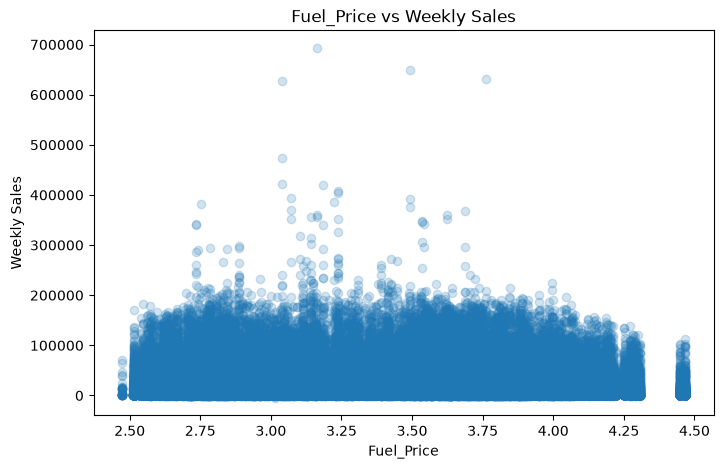

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    train_merged["Fuel_Price"],
    train_merged["Weekly_Sales"],
    alpha=0.2
)

plt.xlabel("Fuel_Price")
plt.ylabel("Weekly Sales")
plt.title("Fuel_Price vs Weekly Sales")

plt.show()

In [ ]:
# Fuel price , CPI, Unemployment showed virtually no linear correlation with weekly sales, suggesting that fuel price alone does not
#  explain overall variations in Walmart weekly sales. 

In [25]:
train_merged[["CPI", "Weekly_Sales"]].corr()

,CPI,Weekly_Sales
CPI,1.000000,-0.020921
Weekly_Sales,-0.020921,1.000000


In [26]:
train_merged[["Unemployment", "Weekly_Sales"]].corr()

,Unemployment,Weekly_Sales
Unemployment,1.000000,-0.025864
Weekly_Sales,-0.025864,1.000000


In [28]:
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

train_merged["Total_MarkDown"] = train_merged[markdown_cols].sum(axis=1)

In [30]:
train_merged[["Total_MarkDown", "Weekly_Sales"]].corr() 

,Total_MarkDown,Weekly_Sales
Total_MarkDown,1.000000,0.065237
Weekly_Sales,0.065237,1.000000


In [32]:
train_merged["Has_MarkDown"] = (
    train_merged["Total_MarkDown"] > 0
)

markdown_comparison = (
    train_merged
    .groupby("Has_MarkDown")["Weekly_Sales"]
    .agg(["mean", "median", "count"])
)

markdown_comparison

,mean,median,count
Has_MarkDown,,,
False,15871.522017,7654.845,270138
True,16177.015244,7537.870,151432


In [33]:
# Markdown activity showed only a weak positive relationship with weekly sales (r = 0.0652). Average sales were slightly higher during 
# weeks with markdown activity (16,177) than weeks without markdown activity (15,872), but the difference was relatively small. 
# This suggests that markdowns alone do not strongly explain overall sales variation.

In [34]:
dept_sales = (
    train_merged
    .groupby("Dept")["Weekly_Sales"]
    .mean()
    .sort_values(ascending=False)
)

dept_sales.head(10)

Dept
92    75204.870531
95    69824.423080
38    61090.619568
72    50566.515417
65    45441.706224
90    45232.084488
40    44900.702727
2     43607.020113
91    33687.910758
94    33405.883963
Name: Weekly_Sales, dtype: float64

In [36]:
dept_sales.tail(10)  

Dept
99    415.487065
60    347.370229
77    328.961800
54    108.305985
45     23.211586
51     21.931729
39     11.123750
78      7.296638
43      1.193333
47     -7.682554
Name: Weekly_Sales, dtype: float64

In [37]:
store_dept_sales = (
    train_merged
    .groupby(["Store", "Dept"])["Weekly_Sales"]
    .mean()
    .sort_values(ascending=False)
)

store_dept_sales.head(10)

Store  Dept
14     92      182527.956014
2      92      164840.230979
20     92      164633.741538
13     92      162034.099301
4      92      159365.107902
20     95      150613.955385
4      95      147236.473706
27     92      146518.141399
14     95      144446.932517
2      95      143588.751888
Name: Weekly_Sales, dtype: float64

In [39]:
train_merged["Year"] = train_merged["Date"].dt.year
train_merged["Month"] = train_merged["Date"].dt.month

In [40]:
train_merged[["Date", "Year", "Month"]].head()

,Date,Year,Month
0,2010-02-05,2010,2
1,2010-02-12,2010,2
2,2010-02-19,2010,2
3,2010-02-26,2010,2
4,2010-03-05,2010,3


In [42]:
yearly_sales = (
    train_merged
    .groupby("Year")["Weekly_Sales"]
    .agg(["mean", "median", "sum", "count"])
)

yearly_sales  

,mean,median,sum,count
Year,,,,
2010,16270.275737,7964.300,2.288886e+09,140679
2011,15954.070675,7522.020,2.448200e+09,153453
2012,15694.948597,7365.095,2.000133e+09,127438


In [43]:
train_merged["WeekOfYear"] = (
    train_merged["Date"].dt.isocalendar().week.astype(int)
)

In [44]:
train_merged[["Date", "Year", "Month", "WeekOfYear"]].head(10)

,Date,Year,Month,WeekOfYear
0,2010-02-05,2010,2,5
1,2010-02-12,2010,2,6
2,2010-02-19,2010,2,7
3,2010-02-26,2010,2,8
4,2010-03-05,2010,3,9
5,2010-03-12,2010,3,10
6,2010-03-19,2010,3,11
7,2010-03-26,2010,3,12
8,2010-04-02,2010,4,13
9,2010-04-09,2010,4,14


In [45]:
train_merged = train_merged.sort_values(
    ["Store", "Dept", "Date"]
)

In [53]:
# lag 1
train_merged["Lag_1"] = (
    train_merged
    .groupby(["Store", "Dept"])["Weekly_Sales"]
    .shift(1)
)

In [ ]:
train_merged[
    ["Store", "Dept", "Date", "Weekly_Sales", "Lag_1"]
].head(15)

,Store,Dept,Date,Weekly_Sales,Lag_1
0,1,1,2010-02-05,24924.50,NaN
1,1,1,2010-02-12,46039.49,24924.50
2,1,1,2010-02-19,41595.55,46039.49
3,1,1,2010-02-26,19403.54,41595.55
4,1,1,2010-03-05,21827.90,19403.54
5,1,1,2010-03-12,21043.39,21827.90
6,1,1,2010-03-19,22136.64,21043.39
7,1,1,2010-03-26,26229.21,22136.64
8,1,1,2010-04-02,57258.43,26229.21
9,1,1,2010-04-09,42960.91,57258.43


In [54]:
# Lag 4
train_merged["Lag_4"] = (
    train_merged
    .groupby(["Store", "Dept"])["Weekly_Sales"]
    .shift(4)
)

In [49]:
train_merged[
    ["Store", "Dept", "Date", "Weekly_Sales", "Lag_1", "Lag_4"]
].head(10)

,Store,Dept,Date,Weekly_Sales,Lag_1,Lag_4
0,1,1,2010-02-05,24924.50,NaN,NaN
1,1,1,2010-02-12,46039.49,24924.50,NaN
2,1,1,2010-02-19,41595.55,46039.49,NaN
3,1,1,2010-02-26,19403.54,41595.55,NaN
4,1,1,2010-03-05,21827.90,19403.54,24924.50
5,1,1,2010-03-12,21043.39,21827.90,46039.49
6,1,1,2010-03-19,22136.64,21043.39,41595.55
7,1,1,2010-03-26,26229.21,22136.64,19403.54
8,1,1,2010-04-02,57258.43,26229.21,21827.90
9,1,1,2010-04-09,42960.91,57258.43,21043.39


In [55]:
# Lag 52
train_merged["Lag_52"] = (
    train_merged
    .groupby(["Store", "Dept"])["Weekly_Sales"]
    .shift(52)
)

In [57]:
# 4 week rolling average
train_merged["Rolling_4"] = (
    train_merged
    .groupby(["Store", "Dept"])["Weekly_Sales"]
    .transform(
        lambda x: x.shift(1).rolling(4).mean()
    )
)

In [58]:
train_merged[
    ["Store", "Dept", "Date", "Weekly_Sales", "Lag_1", "Rolling_4"]
].head(10)

,Store,Dept,Date,Weekly_Sales,Lag_1,Rolling_4
0,1,1,2010-02-05,24924.50,NaN,NaN
1,1,1,2010-02-12,46039.49,24924.50,NaN
2,1,1,2010-02-19,41595.55,46039.49,NaN
3,1,1,2010-02-26,19403.54,41595.55,NaN
4,1,1,2010-03-05,21827.90,19403.54,32990.7700
5,1,1,2010-03-12,21043.39,21827.90,32216.6200
6,1,1,2010-03-19,22136.64,21043.39,25967.5950
7,1,1,2010-03-26,26229.21,22136.64,21102.8675
8,1,1,2010-04-02,57258.43,26229.21,22809.2850
9,1,1,2010-04-09,42960.91,57258.43,31666.9175


In [60]:
train_merged[
    ["Lag_1", "Lag_4", "Lag_52", "Rolling_4"] 
].isnull().sum()

Lag_1          3331
Lag_4         13134
Lag_52       160487
Rolling_4     13134
dtype: int64

In [61]:
train_merged["Rolling_12"] = (
    train_merged
    .groupby(["Store", "Dept"])["Weekly_Sales"]
    .transform(
        lambda x: x.shift(1).rolling(12).mean()
    )
)

In [63]:
# 52 week rolling average
train_merged["Rolling_52"] = (
    train_merged
    .groupby(["Store", "Dept"])["Weekly_Sales"]
    .transform(
        lambda x: x.shift(1).rolling(52).mean()
    )
)

In [67]:
train_merged.columns.tolist()

['Store',
 'Dept',
 'Date',
 'Weekly_Sales',
 'IsHoliday',
 'Temperature',
 'Fuel_Price',
 'MarkDown1',
 'MarkDown2',
 'MarkDown3',
 'MarkDown4',
 'MarkDown5',
 'CPI',
 'Unemployment',
 'Type',
 'Size',
 'Total_MarkDown',
 'Has_MarkDown',
 'Year',
 'Month',
 'WeekOfYear',
 'Lag_1',
 'Lag_4',
 'Lag_52',
 'Rolling_4',
 'Rolling_12',
 'Rolling_52']

In [68]:
train_merged.shape

(421570, 27)

In [69]:
train_merged.isnull().sum().sort_values(ascending=False)

Lag_52            160487
Rolling_52        160487
Rolling_12         38615
Lag_4              13134
Rolling_4          13134
Lag_1               3331
IsHoliday              0
Weekly_Sales           0
Store                  0
Dept                   0
Date                   0
MarkDown4              0
MarkDown3              0
MarkDown2              0
MarkDown1              0
Fuel_Price             0
Temperature            0
MarkDown5              0
CPI                    0
Year                   0
Has_MarkDown           0
Total_MarkDown         0
Size                   0
Type                   0
Unemployment           0
Month                  0
WeekOfYear             0
dtype: int64

In [70]:
train_merged.dropna(
    subset=[
        "Lag_1",
        "Lag_4",
        "Lag_52",
        "Rolling_4",
        "Rolling_12",
        "Rolling_52"
    ]
).shape

(261083, 27)

In [71]:
model_data = train_merged.dropna(
    subset=[
        "Lag_1",
        "Lag_4",
        "Lag_52",
        "Rolling_4",
        "Rolling_12",
        "Rolling_52"
    ]
).copy()

In [72]:
model_data.shape

(261083, 27)

In [73]:
model_data.isnull().sum().sum()

np.int64(0)

In [74]:
model_data["Date"].agg(["min", "max"])

min   2011-02-04
max   2012-10-26
Name: Date, dtype: datetime64[us]

In [76]:
cutoff_date = pd.Timestamp("2012-07-01")

train_data = model_data[
    model_data["Date"] < cutoff_date
].copy()

validation_data = model_data[
    model_data["Date"] >= cutoff_date
].copy()

In [77]:
print("Training:", train_data.shape)
print("Validation:", validation_data.shape)

Training: (211666, 27)
Validation: (49417, 27)


In [78]:
print("Training dates:", train_data["Date"].min(), "to", train_data["Date"].max())
print("Validation dates:", validation_data["Date"].min(), "to", validation_data["Date"].max())

Training dates: 2011-02-04 00:00:00 to 2012-06-29 00:00:00
Validation dates: 2012-07-06 00:00:00 to 2012-10-26 00:00:00


In [79]:
X_train = train_data.drop(
    columns=["Weekly_Sales", "Date"]
)

y_train = train_data["Weekly_Sales"]

X_validation = validation_data.drop(
    columns=["Weekly_Sales", "Date"]
)

y_validation = validation_data["Weekly_Sales"]

In [80]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

X_train: (211666, 25)
y_train: (211666,)
X_validation: (49417, 25)
y_validation: (49417,)


In [85]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

categorical_cols = ["Store", "Dept", "Type"]

In [86]:
X_train_encoded = encoder.fit_transform(X_train[categorical_cols])
X_validation_encoded = encoder.transform(X_validation[categorical_cols])

In [87]:
numerical_cols = [
    col for col in X_train.columns
    if col not in ["Store", "Dept", "Type"]
]

X_train_numeric = X_train[numerical_cols]
X_validation_numeric = X_validation[numerical_cols]

In [88]:
import numpy as np

X_train_final = np.hstack([
    X_train_numeric.values,
    X_train_encoded
])

X_validation_final = np.hstack([
    X_validation_numeric.values,
    X_validation_encoded
])

In [89]:
X_train_final.shape, X_validation_final.shape

((211666, 145), (49417, 145))

In [91]:
# Random forest regressor model
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [92]:
rf_model.fit(X_train_final, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [93]:
y_pred = rf_model.predict(X_validation_final)

In [94]:
comparison = pd.DataFrame({
    "Actual": y_validation.values[:10],
    "Predicted": y_pred[:10]
})

comparison

,Actual,Predicted
0,17823.37,17161.3910
1,16566.18,17526.2499
2,16348.06,16525.3989
3,15731.18,16680.7730
4,16628.31,16450.1271
5,16119.92,16444.1488
6,17330.70,16039.8623
7,16286.40,16733.6484
8,16680.24,16563.3571
9,18322.37,18162.2570


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_validation, y_pred)

rmse = np.sqrt(mean_squared_error(y_validation, y_pred))

mape = np.mean(
    np.abs((y_validation - y_pred) / y_validation)
) * 100

print("MAE:", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

MAE: 1230.3760703037417
RMSE: 2532.1556895882522
MAPE: inf %


In [96]:
baseline_pred = validation_data["Lag_1"]

In [ ]:
baseline_mae = mean_absolute_error(
    y_validation,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        baseline_pred
    )
)

print("Baseline MAE:", baseline_mae) 
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 1574.391172471012
Baseline RMSE: 3513.106584322563


In [98]:
wape = (
    np.sum(np.abs(y_validation - y_pred))
    / np.sum(np.abs(y_validation))
) * 100

baseline_wape = (
    np.sum(np.abs(y_validation - baseline_pred))
    / np.sum(np.abs(y_validation))
) * 100

print("Random Forest WAPE:", wape, "%")
print("Baseline WAPE:", baseline_wape, "%")

Random Forest WAPE: 7.703431472110562 %
Baseline WAPE: 9.857323138958773 %


In [ ]:
Gradient boosting
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

gb_model.fit(X_train_final, y_train)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

gb_pred = gb_model.predict(X_validation_final)

gb_mae = mean_absolute_error(y_validation, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_validation, gb_pred))
gb_wape = (
    np.abs(y_validation.values - gb_pred).sum()
    / np.abs(y_validation.values).sum()
) * 100

print(f"Gradient Boosting MAE: {gb_mae:.2f}")
print(f"Gradient Boosting RMSE: {gb_rmse:.2f}")
print(f"Gradient Boosting WAPE: {gb_wape:.2f}%")

In [ ]:
results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest", "Gradient Boosting"],
    "MAE": [1574, 1230, gb_mae],
    "RMSE": [3513, 2532, gb_rmse],
    "WAPE (%)": [9.8, 7.7, gb_wape]
})

print(results.round(2).to_string(index=False))
best_model_name = results.loc[results["MAE"].idxmin(), "Model"]
print("\nBest model by MAE:", best_model_name)

In [ ]:
from sklearn.inspection import permutation_importance

sample_size = min(3000, len(X_validation_final))
rng = np.random.default_rng(42)
idx = rng.choice(len(X_validation_final), sample_size, replace=False)

importance = permutation_importance(
    gb_model,
    X_validation_final[idx],
    y_validation.iloc[idx],
    scoring="neg_mean_absolute_error",
    n_repeats=2,
    random_state=42,
    n_jobs=-1
)

feature_names = numerical_cols + list(
    encoder.get_feature_names_out(categorical_cols)
)

feature_importance = pd.Series(
    importance.importances_mean,
    index=feature_names
).sort_values(ascending=False)

print(feature_importance.head(15))

In [ ]:
if best_model_name == "Random Forest":
    final_model = RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    )
else:
    final_model = HistGradientBoostingRegressor(
        max_iter=150, learning_rate=0.1,
        max_leaf_nodes=31, random_state=42
    )

X_all = model_data.drop(columns=["Weekly_Sales", "Date"])
y_all = model_data["Weekly_Sales"]

X_all_num = X_all[numerical_cols]
X_all_cat = encoder.transform(X_all[categorical_cols])
X_all_final = np.hstack([X_all_num.values, X_all_cat])

final_model.fit(X_all_final, y_all)

In [ ]:
test_merged = test.merge(
    features, on=["Store", "Date"], how="left"
).merge(
    stores, on="Store", how="left"
)

test_merged["Date"] = pd.to_datetime(test_merged["Date"])
test_merged["WeekOfYear"] = (
    test_merged["Date"].dt.isocalendar().week.astype(int)
)

test_merged["Year"] = test_merged["Date"].dt.year
test_merged["Month"] = test_merged["Date"].dt.month

test_merged["Total_MarkDown"] = test_merged[
    ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
].sum(axis=1)

test_merged = test_merged.sort_values(["Store", "Dept", "Date"])

In [ ]:
history = train_merged.sort_values(["Store", "Dept", "Date"]).copy()
history_sales = {
    key: group.set_index("Date")["Weekly_Sales"].to_dict()
    for key, group in history.groupby(["Store", "Dept"])
}

markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
forecast_rows = []

for date in sorted(test_merged["Date"].unique()):
    batch = test_merged[test_merged["Date"] == date].copy()

    lag_values = []
    rolling_values = []

    for row in batch.itertuples(index=False):
        key = (row.Store, row.Dept)
        sales_history = history_sales.get(key, {})
        past_dates = sorted(d for d in sales_history if d < date)

        last_sales = [sales_history[d] for d in past_dates]

        lag_values.append([
            last_sales[-1] if len(last_sales) >= 1 else 0,
            last_sales[-4] if len(last_sales) >= 4 else 0,
            last_sales[-52] if len(last_sales) >= 52 else 0,
            np.mean(last_sales[-4:]) if len(last_sales) >= 4 else 0,
            np.mean(last_sales[-12:]) if len(last_sales) >= 12 else 0,
            np.mean(last_sales[-52:]) if len(last_sales) >= 52 else 0
        ])

    batch[["Lag_1", "Lag_4", "Lag_52",
           "Rolling_4", "Rolling_12", "Rolling_52"]] = lag_values

    # Match the exact numerical feature order used during training
    X_batch_num = batch[numerical_cols]
    X_batch_cat = encoder.transform(batch[categorical_cols])
    X_batch_final = np.hstack([X_batch_num.values, X_batch_cat])

    predictions = final_model.predict(X_batch_final)
    batch["Predicted_Weekly_Sales"] = predictions

    for row, prediction in zip(batch.itertuples(index=False), predictions):
        history_sales.setdefault((row.Store, row.Dept), {})[date] = prediction

    forecast_rows.append(batch)

In [ ]:
forecast_df = pd.concat(forecast_rows, ignore_index=True)

final_forecasts = forecast_df[
    ["Store", "Dept", "Date", "Predicted_Weekly_Sales"]
].sort_values(["Date", "Store", "Dept"])

final_forecasts.to_csv("walmart_sales_forecasts.csv", index=False)

print(final_forecasts.head())
print("Forecast shape:", final_forecasts.shape)
print("Missing predictions:", final_forecasts["Predicted_Weekly_Sales"].isna().sum())